In [30]:
import argparse
import demes
import demesdraw
import h2py
from h2py.utils import timestamp
import matplotlib.pyplot as plt 
import matplotlib as mpl
from matplotlib.transforms import ScaledTranslation
import moments
import numpy as np
import pickle
import scipy
import sys
import time


mpl.rc("xtick", labelsize=7)
mpl.rc("ytick", labelsize=7)
mpl.rc("font", size=8)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize=8)
mpl.rc("legend", fontsize=7)
mpl.rc("axes", titlesize="small")

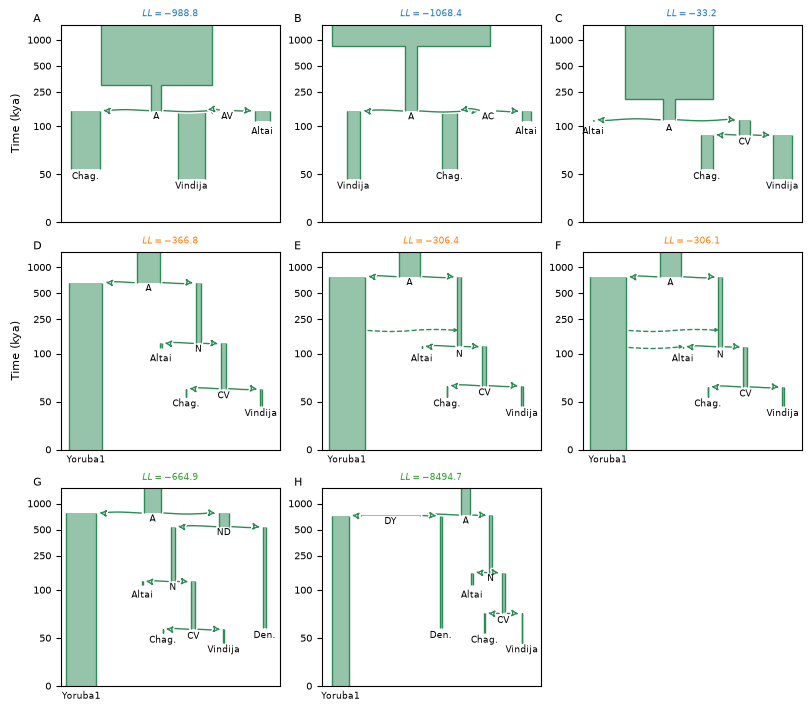

In [81]:
# Generate the figure

graph_color = "seagreen"
mosaic = "ABC;DEF;GH."
fig, axs = plt.subplot_mosaic(mosaic, figsize=(8, 7), layout="constrained")


def setup(ax):
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    return


def label_demes(ax, graph, positions, alias=None):
    end_times = dict()
    for deme in graph.demes:
        end_times[deme.name] = deme.epochs[-1].end_time
    def func(y):
        # scale y-position according to end time
        if y > 1e5:
            return 0.8 * y
        else:
            return y - 1e4
    # For demes with end time 0, make x-axis labels
    xlabels = []
    xpoints = []
    floating = dict()
    for name, end_time in end_times.items():
        if name in alias:
            label = alias[name]
        else:
            label = name
        if end_time == 0:
            xlabels.append(label)
            xpoints.append(positions[name])
        else:
            floating[label] = (positions[name], func(end_time))
    ax.set_xticks(xpoints, xlabels, fontsize="small")
    for label, (x, y) in floating.items():
        ax.text(x, y, label, horizontalalignment="center", fontsize="small")
    return


def plot_misspec_triplet1(ax):
    graph = demes.load("fit_models/triplet_AV_C.yaml")
    positions = {
        "A": 0, 
        "AV": 1e4,
        "Chagyrskaya": -1e4,
        "Altai": 1.5e4,
        "Vindija": 5e3,
    }
    demesdraw.tubes(
        graph,
        ax=ax,
        colours=graph_color,
        log_time=True,
        labels=None,
        positions=positions,
    )
    label_demes(ax, graph, positions, alias={"Chagyrskaya": "Chag."}) 
    ax.set_title("$LL=-988.8$", color="tab:blue")
    ax.set_yscale("symlog", linthresh=1e5)
    ax.set_ylim(0, 1.5e6)
    yticks = [0, 5e4, 1e5, 2.5e5, 5e5, 1e6]
    ax.set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
    setup(ax)
    return


def plot_misspec_triplet2(ax):
    graph = demes.load("fit_models/triplet_AC_V.yaml")
    positions = {
        "A": 0, 
        "AC": 2e4,
        "Vindija": -1.5e4,
        "Altai": 3e4,
        "Chagyrskaya": 1e4,
    }
    demesdraw.tubes(
        graph,
        ax=ax,
        colours=graph_color,
        log_time=True,
        labels=None,
        positions=positions,
    )
    label_demes(ax, graph, positions, alias={"Chagyrskaya": "Chag."}) 
    ax.set_title("$LL=-1068.4$", color="tab:blue")
    ax.set_yscale("symlog", linthresh=1e5)
    ax.set_ylim(0, 1.5e6)
    yticks = [0, 5e4, 1e5, 2.5e5, 5e5, 1e6]
    ax.set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
    setup(ax)
    return


def plot_triplet(ax):
    graph = demes.load("fit_models/triplet_CV_A.yaml")
    positions = {
        "A": 0, 
        "Altai": -1e4,
        "Vindija": 1.5e4,
        "CV": 1e4,
        "Chagyrskaya": 5e3,
    }
    demesdraw.tubes(
        graph,
        ax=ax,
        colours=graph_color,
        log_time=True,
        labels=None,
        positions=positions,
    )
    label_demes(ax, graph, positions, alias={"Chagyrskaya": "Chag."}) 
    ax.set_title("$LL=-33.2$", color="tab:blue")
    ax.set_yscale("symlog", linthresh=1e5)
    ax.set_ylim(0, 1.5e6)
    yticks = [0, 5e4, 1e5, 2.5e5, 5e5, 1e6]
    ax.set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
    setup(ax)
    return


def plot_yoruba_added(ax):
    positions = {
        "A": -2e4,
        "Yoruba1": -7e4,
        "N": 2e4, 
        "Altai": -1e4,
        "Vindija": 7e4,
        "CV": 4e4,
        "Chagyrskaya": 1e4,
    }
    graph = demes.load("fit_models/quartet_Yoruba_2.yaml")
    demesdraw.tubes(
        graph,
        ax=ax,
        colours=graph_color,
        log_time=True,
        labels=None,
        positions=positions,
    )
    label_demes(ax, graph, positions, alias={"Chagyrskaya": "Chag."}) 
    ax.set_title("$LL=-366.8$", color="tab:orange")
    ax.set_yscale("symlog", linthresh=1e5)
    ax.set_ylim(0, 1.5e6)
    yticks = [0, 5e4, 1e5, 2.5e5, 5e5, 1e6]
    ax.set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
    ax.set_xlim(-9e4, 8.5e4)
    setup(ax)
    return


def plot_pulse_model_1(ax):
    graph = demes.load("fit_models/quartet_Yoruba_2_pulse1.yaml")
    positions = {
        "A": -2e4,
        "Yoruba1": -7e4,
        "N": 2e4, 
        "Altai": -1e4,
        "Vindija": 7e4,
        "CV": 4e4,
        "Chagyrskaya": 1e4,
    }
    demesdraw.tubes(
        graph,
        ax=ax,
        colours=graph_color,
        log_time=True,
        labels=None,
        positions=positions,
    )
    label_demes(ax, graph, positions, alias={"Chagyrskaya": "Chag."}) 
    ax.set_title("$LL=-306.4$", color="tab:orange")
    ax.set_yscale("symlog", linthresh=1e5)
    ax.set_ylim(0, 1.5e6)
    yticks = [0, 5e4, 1e5, 2.5e5, 5e5, 1e6]
    ax.set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
    ax.set_xlim(-9e4, 8.5e4)
    setup(ax)
    return


def plot_pulse_model_2(ax):
    graph = demes.load("fit_models/quartet_Yoruba_2_pulse2.yaml")
    positions = {
        "A": -2e4,
        "Yoruba1": -7e4,
        "N": 2e4, 
        "Altai": -1e4,
        "Vindija": 7e4,
        "CV": 4e4,
        "Chagyrskaya": 1e4,
    }
    demesdraw.tubes(
        graph,
        ax=ax,
        colours=graph_color,
        log_time=True,
        labels=None,
        positions=positions,
    )
    label_demes(ax, graph, positions, alias={"Chagyrskaya": "Chag."}) 
    ax.set_title("$LL=-306.1$", color="tab:orange")
    ax.set_yscale("symlog", linthresh=1e5)
    ax.set_ylim(0, 1.5e6)
    yticks = [0, 5e4, 1e5, 2.5e5, 5e5, 1e6]
    ax.set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
    ax.set_xlim(-9e4, 8.5e4)
    setup(ax)
    return


def plot_denisova_model_1(ax):
    graph = demes.load("fit_models/quintet_Denisova.yaml")
    positions = {
        "A": 0,
        "Yoruba1": -7e4,
        "ND": 7e4, 
        "Denisova": 1.1e5,
        "N": 2e4, 
        "Altai": -1e4,
        "Vindija": 7e4,
        "CV": 4e4,
        "Chagyrskaya": 1e4,
    }
    demesdraw.tubes(
        graph,
        ax=ax,
        colours=graph_color,
        log_time=True,
        labels=None,
        positions=positions,
    )
    label_demes(ax, graph, positions, alias={"Chagyrskaya": "Chag.", "Denisova": "Den."}) 
    ax.set_title("$LL=-664.9$", color="tab:green")
    ax.set_yscale("symlog", linthresh=1e5)
    ax.set_ylim(0, 1.5e6)
    yticks = [0, 5e4, 1e5, 2.5e5, 5e5, 1e6]
    ax.set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
    ax.set_xlim(-9e4, 1.25e5)
    setup(ax)
    return


def plot_denisova_model_2(ax):
    graph = demes.load("fit_models/quintet_Denisova_after_Feng.yaml")
    positions = {
        "A": -2e4,
        "Yoruba1": -2.2e5,
        "DY": -1.4e5, 
        "Denisova": -6e4,
        "N": 2e4, 
        "Altai": -1e4,
        "Vindija": 7e4,
        "CV": 4e4,
        "Chagyrskaya": 1e4,
    }
    demesdraw.tubes(
        graph,
        ax=ax,
        colours=graph_color,
        log_time=True,
        labels=None,
        positions=positions,
    )
    label_demes(ax, graph, positions, alias={"Chagyrskaya": "Chag.", "Denisova": "Den."}) 
    ax.set_title("$LL=-8494.7$", color="tab:green")
    ax.set_yscale("symlog", linthresh=1e5)
    ax.set_ylim(0, 1.5e6)
    yticks = [0, 5e4, 1e5, 2.5e5, 5e5, 1e6]
    ax.set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
    ax.set_xlim(-2.5e5, 1e5)
    setup(ax)
    return


plot_misspec_triplet1(axs["A"])
plot_misspec_triplet2(axs["B"])
plot_triplet(axs["C"])
plot_yoruba_added(axs["D"])
plot_pulse_model_1(axs["E"])
plot_pulse_model_2(axs["F"])
plot_denisova_model_1(axs["G"])
plot_denisova_model_2(axs["H"])


for lab in axs:
    if lab in ("A", "D"):
        axs[lab].set_ylabel("Time (kya)")
    else:
        axs[lab].set_ylabel(None)


for label, ax in axs.items():
    ax.text(0.0, 1.0, label, fontsize="medium", va="bottom", transform=(
        ax.transAxes + ScaledTranslation(-20/72, +0/72, fig.dpi_scale_trans)))
    
plt.savefig("../../figures/exploring_model_space.pdf")

In [24]:
graph = demes.load("fit_models/quintet_Denisova_after_Feng.yaml")
graph.demes[0].epochs[-1].end_time

735211.9927173371

In [3]:
data_file = "../bootstrapped_data/accessible_1e-4M_ccds_flank_bherer_adj.pkl"
with open(data_file, "rb") as fin:
    full_data = pickle.load(fin)

def fit_model(model, options, out, max_iter=3000, method="lbfgsb"):
    # Fit a model using the Powell algorithm
    graph = demes.load(model)
    deme_names = [d.name for d in graph.demes]
    pops = [p for p in full_data["pops"] if p in deme_names]
    data = h2py.parsing.subset_data(full_data, to_pops=pops)
    pnames, pvals, ll0 = h2py.inference.optimize(
        model,
        options,
        data["means"],
        data["varcovs"],
        method=method,
        pops=data["pops"],
        r_bins=data["bins"],
        u=1.3e-8,
        use_log=True,
        max_iter=max_iter,
        report=25,
        output=out,
        overwrite=True
    )
    return pnames, pvals, ll0

In [18]:
fit_model("models/triplet_CV_A.yaml", "models/triplet_CV_A_options.yaml", 
          "fit_models/triplet_CV_A.yaml")

[26-10-21 21:45:17] Fitting to observed H2 for ['Altai', 'Vindija', 'Chagyrskaya']
Call         LL [     T_Bot    T_A_CV      T_CV       N_A       N_N     N_Vin     N_Alt     N_Cha]
init          - [     8e+05     4e+05     1e+05   1.6e+04     3e+03     1e+03     1e+03     1e+03]
25    -19776.29 [     8e+05     4e+05  1.18e+05   1.6e+04     3e+03     1e+03     1e+03     1e+03]
50     -3664.26 [  8.62e+05  3.07e+05  1.29e+05  1.52e+04  2.55e+03     1e+03     1e+03     1e+03]
75      -2742.8 [  8.09e+05  2.78e+05  2.03e+05  1.54e+04  2.44e+03  1.01e+03  1.01e+03  1.01e+03]
100     -561.67 [  4.68e+05  1.22e+05  8.27e+04  1.86e+04  2.72e+03  1.11e+03  1.15e+03  1.13e+03]
125     -519.28 [  4.82e+05  1.27e+05  8.62e+04  1.84e+04   2.7e+03   1.1e+03  1.14e+03  1.12e+03]
150    -9083.55 [  4.92e+05  1.99e+05  6.05e+04   1.9e+04   3.3e+03  1.18e+03  1.08e+03  1.13e+03]
175     -178.56 [  4.86e+05  1.39e+05  7.54e+04  1.79e+04  2.97e+03  1.18e+03  1.11e+03  1.11e+03]
200      -65.31 [  5.21e+0

(['T_Bot', 'T_A_CV', 'T_CV', 'N_A', 'N_N', 'N_Vin', 'N_Alt', 'N_Cha'],
 array([2.06569717e+05, 1.18894160e+05, 9.09515253e+04, 1.16524582e+04,
        1.55368092e+03, 2.45720165e+03, 1.57452041e+02, 1.64638681e+03]),
 np.float64(-33.12148361019315))

In [25]:
fit_model("models/triplet_AV_C.yaml", "models/triplet_AV_C_options.yaml", 
          "fit_models/triplet_AV_C.yaml", method="powell")

[26-10-21 21:55:17] Fitting to observed H2 for ['Altai', 'Vindija', 'Chagyrskaya']
Call         LL [     T_Bot    T_C_AV      T_AV       N_A       N_N       N_N     N_Vin     N_Alt     N_Cha]
init          - [     8e+05     4e+05   1.5e+05   1.6e+04     3e+03     3e+03     1e+03     1e+03     1e+03]
25     -4826.28 [  9.99e+05  2.25e+05   1.5e+05   1.6e+04     3e+03     3e+03     1e+03     1e+03     1e+03]
50     -2575.65 [  9.99e+05  1.52e+05  1.52e+05   1.6e+04     3e+03     3e+03     1e+03     1e+03     1e+03]
75     -3029.71 [  9.99e+05  1.52e+05  1.52e+05  4.72e+04     3e+03  2.28e+03     1e+03     1e+03     1e+03]
100    -2038.19 [  9.99e+05  1.52e+05  1.52e+05  4.72e+04     3e+03  2.95e+03  2.16e+03  2.22e+03     1e+03]
125    -1224.49 [  8.89e+05  1.52e+05  1.52e+05  4.72e+04     3e+03  2.95e+03  2.16e+03  2.22e+03  3.99e+03]
150    -1224.13 [   8.9e+05  1.52e+05  1.52e+05  4.72e+04     3e+03  2.95e+03  2.16e+03  2.22e+03  3.99e+03]
200    -2109.25 [   8.9e+05  1.52e+05  1.52e+

(['T_Bot', 'T_C_AV', 'T_AV', 'N_A', 'N_N', 'N_N', 'N_Vin', 'N_Alt', 'N_Cha'],
 array([302567.78878512, 151728.88331616, 151728.88331582,  15738.47105349,
          3000.        ,   1379.27242031,   3704.76530134,   2128.1635209 ,
          4117.15702652]),
 np.float64(-988.7957505105237))

In [27]:
fit_model("models/triplet_AC_V.yaml", "models/triplet_AC_V_options.yaml", 
          "fit_models/triplet_AC_V.yaml", method="powell")

[26-10-21 22:13:42] Fitting to observed H2 for ['Altai', 'Vindija', 'Chagyrskaya']
Call         LL [     T_Bot    T_V_AC      T_AC       N_A       N_N       N_N     N_Vin     N_Alt     N_Cha]
init          - [     8e+05     4e+05   1.5e+05   1.6e+04     3e+03     3e+03     1e+03     1e+03     1e+03]
25    -15258.13 [  9.98e+05  2.94e+05   1.5e+05   1.6e+04     3e+03     3e+03     1e+03     1e+03     1e+03]
50     -2569.78 [  9.98e+05   1.5e+05   1.5e+05   1.6e+04     3e+03     3e+03     1e+03     1e+03     1e+03]
75   -595394.84 [  9.98e+05   1.5e+05   1.5e+05  4.81e+04     3e+03  8.15e+03     1e+03     1e+03     1e+03]
100    -2020.86 [  9.98e+05   1.5e+05   1.5e+05  4.81e+04     3e+03  2.95e+03  2.15e+03  1.86e+03     1e+03]
125    -1218.91 [  8.92e+05   1.5e+05   1.5e+05  4.81e+04     3e+03  2.95e+03  2.15e+03  2.12e+03  3.94e+03]
225     -2476.0 [  8.92e+05   1.5e+05   1.5e+05  4.79e+04     3e+03  2.26e+03  2.15e+03  2.12e+03  3.94e+03]
250    -1098.01 [  8.92e+05   1.5e+05   1.5e+

(['T_Bot', 'T_V_AC', 'T_AC', 'N_A', 'N_N', 'N_N', 'N_Vin', 'N_Alt', 'N_Cha'],
 array([847827.02347226, 150308.0787092 , 150308.07870879,  41256.21000521,
          3000.        ,   3009.26889302,   3608.54675238,   2302.53494246,
          4023.68241687]),
 np.float64(-1068.382765544193))

In [26]:
fit_model("models/quartet_Yoruba.yaml", "models/quartet_Yoruba_options.yaml", 
          "fit_models/quartet_Yoruba.yaml")

[26-10-21 22:06:29] Fitting to observed H2 for ['Altai', 'Vindija', 'Chagyrskaya', 'Yoruba1']
Call         LL [      T_NY     T_Bot    T_A_CV      T_CV       N_A       N_Y      N_N0      N_N1     N_Vin     N_Alt     N_Cha]
init          - [     7e+05  2.07e+05  1.19e+05   9.1e+04     1e+04     1e+04  1.17e+04  1.55e+03  2.46e+03  1.57e+02  1.65e+03]
25    -12310.42 [     7e+05  2.66e+05  1.19e+05  9.09e+04     1e+04     1e+04  1.17e+04  1.55e+03  2.46e+03  1.57e+02  1.65e+03]
50     -7846.07 [  8.36e+05   2.2e+05  1.23e+05  9.02e+04  1.33e+04  1.23e+04  1.16e+04  1.56e+03  2.41e+03  1.58e+02  1.66e+03]
100    -1446.54 [  6.89e+05  2.82e+05  1.22e+05  9.18e+04  1.63e+04  2.61e+04  1.16e+04   1.6e+03   2.3e+03  1.62e+02  1.68e+03]
125     -486.88 [  7.02e+05  2.47e+05   1.2e+05  9.01e+04   1.8e+04  2.77e+04  1.15e+04  1.58e+03  2.29e+03  1.62e+02  1.68e+03]
150     -447.97 [  7.03e+05  2.45e+05  1.19e+05  9.04e+04  1.77e+04  2.75e+04  1.15e+04  1.59e+03  2.29e+03  1.62e+02  1.68e+03]
175

(['T_NY',
  'T_Bot',
  'T_A_CV',
  'T_CV',
  'N_A',
  'N_Y',
  'N_N0',
  'N_N1',
  'N_Vin',
  'N_Alt',
  'N_Cha'],
 array([7.82327272e+05, 1.64649471e+05, 1.18366142e+05, 8.82288370e+04,
        1.65277065e+04, 3.04080308e+04, 5.94053216e+03, 1.66966857e+03,
        2.56791570e+03, 1.43319216e+02, 1.67159283e+03]),
 np.float64(-337.8012825003329))

In [30]:
fit_model("models/quartet_Yoruba_2.yaml", "models/quartet_Yoruba_options_2.yaml", 
          "fit_models/quartet_Yoruba_2.yaml", method="lbfgsb")
fit_model("fit_models/quartet_Yoruba_2.yaml", "models/quartet_Yoruba_options_2.yaml", 
          "fit_models/quartet_Yoruba_2.yaml", method="powell")

[26-10-21 22:32:12] Fitting to observed H2 for ['Altai', 'Vindija', 'Chagyrskaya', 'Yoruba1']
Call         LL [      T_NY    T_A_CV      T_CV       N_A       N_Y       N_N     N_Vin     N_Alt     N_Cha]
init          - [  6.62e+05  1.31e+05  6.39e+04  1.84e+04  2.62e+04   3.9e+03  1.04e+03  8.16e+02  4.26e+02]
50    -21146.56 [  6.62e+05  1.31e+05  6.38e+04  1.84e+04   5.2e+03   3.9e+03  1.04e+03  8.16e+02  4.26e+02]
75      -406.08 [  6.62e+05  1.31e+05  6.38e+04  1.84e+04  2.63e+04   3.9e+03  1.52e+03  8.16e+02  4.26e+02]
100     -367.18 [  6.62e+05  1.31e+05  6.38e+04  1.84e+04  2.63e+04   3.9e+03  1.08e+03  8.25e+02  4.17e+02]
150   -21140.36 [  6.62e+05  1.31e+05  6.38e+04  1.84e+04  5.22e+03   3.9e+03  1.08e+03  8.25e+02  4.17e+02]
175      -575.2 [  6.62e+05  1.31e+05  6.38e+04  1.84e+04  2.64e+04   3.9e+03  5.81e+02  8.25e+02  4.17e+02]
200     -367.07 [  6.62e+05  1.31e+05  6.38e+04  1.84e+04  2.64e+04   3.9e+03  1.08e+03   8.3e+02  4.11e+02]
225     -367.03 [  6.62e+05  1.31e

(['T_NY', 'T_A_CV', 'T_CV', 'N_A', 'N_Y', 'N_N', 'N_Vin', 'N_Alt', 'N_Cha'],
 array([6.62784496e+05, 1.31278317e+05, 6.34136159e+04, 1.83902311e+04,
        2.63854800e+04, 3.90867079e+03, 1.06382170e+03, 8.58364317e+02,
        3.96360934e+02]),
 np.float64(-366.8525219493899))

In [50]:
fit_model("models/quartet_Yoruba_2_pulse1.yaml", "models/quartet_Yoruba_2_pulse1_options.yaml", 
          "fit_models/quartet_Yoruba_2_pulse1.yaml", method="lbfgsb")
fit_model("fit_models/quartet_Yoruba_2_pulse1.yaml", "models/quartet_Yoruba_2_pulse1_options.yaml", 
          "fit_models/quartet_Yoruba_2_pulse1.yaml", method="powell")

[26-10-21 23:28:54] Fitting to observed H2 for ['Altai', 'Vindija', 'Chagyrskaya', 'Yoruba1']
Call         LL [      T_NY   T_pulse    T_A_CV      T_CV   p_pulse       N_A       N_Y       N_N     N_Vin     N_Alt     N_Cha]
init          - [  7.75e+05  1.84e+05  1.21e+05  6.63e+04     0.051   1.7e+04   2.9e+04  3.14e+03  1.32e+03  2.79e+02   5.4e+02]
25      -308.09 [  7.75e+05  1.84e+05  1.21e+05  6.63e+04     0.051   1.7e+04   2.9e+04  3.14e+03  1.32e+03  2.79e+02   5.4e+02]
50      -308.09 [  7.75e+05  1.84e+05  1.21e+05  6.63e+04     0.051   1.7e+04   2.9e+04  3.14e+03  1.32e+03  2.79e+02   5.4e+02]
75      -308.08 [  7.75e+05  1.84e+05  1.21e+05  6.63e+04    0.0511   1.7e+04   2.9e+04  3.14e+03  1.32e+03  2.79e+02   5.4e+02]
100     -308.08 [  7.75e+05  1.84e+05  1.21e+05  6.63e+04    0.0511   1.7e+04  2.91e+04  3.14e+03  1.32e+03  2.79e+02   5.4e+02]
125     -498.07 [  7.75e+05  1.84e+05  1.21e+05  6.63e+04    0.0511   1.7e+04  2.91e+04  3.14e+03  1.26e+03  2.75e+02  2.91e+02]
150

(['T_NY',
  'T_pulse',
  'T_A_CV',
  'T_CV',
  'p_pulse',
  'N_A',
  'N_Y',
  'N_N',
  'N_Vin',
  'N_Alt',
  'N_Cha'],
 array([7.77802223e+05, 1.86798649e+05, 1.20793056e+05, 6.65226508e+04,
        5.14300125e-02, 1.68995187e+04, 2.91262784e+04, 3.15066350e+03,
        1.25652459e+03, 2.58707835e+02, 5.62829691e+02]),
 np.float64(-306.39943024590264))

In [39]:
fit_model("models/quartet_Yoruba_2_pulse2.yaml", "models/quartet_Yoruba_2_pulse2_options.yaml",
          "fit_models/quartet_Yoruba_2_pulse2.yaml", method="lbfgsb")
fit_model("fit_models/quartet_Yoruba_2_pulse2.yaml", "models/quartet_Yoruba_2_pulse2_options.yaml",
          "fit_models/quartet_Yoruba_2_pulse2.yaml", method="powell")

[26-10-21 23:06:26] Fitting to observed H2 for ['Altai', 'Vindija', 'Chagyrskaya', 'Yoruba1']
Call         LL [      T_NY   T_pulse    T_A_CV      T_CV   p_pulse  p_pulse1       N_A       N_Y       N_N     N_Vin     N_Alt     N_Cha]
init          - [  7.65e+05  1.72e+05   1.2e+05  6.82e+04    0.0465  0.000567  1.71e+04  2.88e+04   3.1e+03  1.37e+03   2.2e+02  6.51e+02]
25       -315.2 [  7.65e+05  1.72e+05   1.2e+05  6.82e+04    0.0465  0.000567  1.71e+04  2.88e+04   3.1e+03  1.37e+03   2.2e+02  6.51e+02]
50       -315.2 [  7.65e+05  1.72e+05   1.2e+05  6.81e+04    0.0465  0.000567  1.71e+04  2.88e+04   3.1e+03  1.37e+03   2.2e+02  6.51e+02]
100     -5624.0 [  7.65e+05  1.72e+05   1.2e+05  6.81e+04    0.0467  1.01e-08  1.71e+04  7.82e+04   3.1e+03  1.37e+03   2.2e+02  6.51e+02]
125     -501.37 [  7.65e+05  1.72e+05   1.2e+05  6.81e+04    0.0467  1.01e-08  1.71e+04  2.88e+04   3.1e+03  7.36e+02   2.2e+02  6.51e+02]
150     -308.65 [  7.65e+05  1.72e+05   1.2e+05  6.81e+04    0.0467  1.0

(['T_NY',
  'T_pulse',
  'T_A_CV',
  'T_CV',
  'p_pulse',
  'p_pulse1',
  'N_A',
  'N_Y',
  'N_N',
  'N_Vin',
  'N_Alt',
  'N_Cha'],
 array([7.73166619e+05, 1.88010049e+05, 1.20000003e+05, 6.53180888e+04,
        5.18570490e-02, 1.00000002e-08, 1.69746714e+04, 2.89854219e+04,
        3.16202830e+03, 1.18464091e+03, 2.20084847e+02, 4.97423178e+02]),
 np.float64(-306.0599744511624))

In [8]:
ll0 = -366.8525219493899
ll1 = -306.39943024590264
ll2 = -306.0599744511624

df_test0 = [0, 0.5, 0.5]
df_test1 = [0.5, 0.5]

lam0 = 2 * (ll1 - ll0)
lam1 = 2 * (ll2 - ll1)

p0 = moments.Godambe.sum_chi2_ppf(lam0, weights=df_test0)
p1 = moments.Godambe.sum_chi2_ppf(lam1, weights=df_test1)

print("one-pulse vs no pulse:", lam0, p0)
print("two-pulse vs one pulse:", lam1, p1)

one-pulse vs no pulse: 120.90618340697449 0.0
two-pulse vs one pulse: 0.6789115894804354 0.20498088322953367


In [4]:
# fit (Yoruba, (Denisova, Neanderthal)) model
fit_model("models/quintet_Denisova.yaml", "models/quintet_Denisova_options.yaml",
          "fit_models/quintet_Denisova.yaml", method="lbfgsb")
fit_model("fit_models/quintet_Denisova.yaml", "models/quintet_Denisova_options.yaml",
          "fit_models/quintet_Denisova.yaml", method="powell")

[26-10-24 09:21:58] Fitting to observed H2 for ['Altai', 'Vindija', 'Chagyrskaya', 'Denisova', 'Yoruba1']
Call         LL [     T_NDY      T_ND    T_A_CV      T_CV       N_A       N_Y      N_ND       N_D       N_N     N_Vin     N_Alt     N_Cha]
init          - [  7.82e+05     7e+05  1.18e+05  8.82e+04  1.65e+04  3.04e+04     5e+03     4e+03     3e+03  2.57e+03  1.43e+02  1.67e+03]
25     -23041.4 [  7.82e+05  2.58e+05  1.18e+05  8.96e+04  1.65e+04  3.04e+04     5e+03     4e+03     3e+03  2.57e+03  1.43e+02  1.67e+03]
50     -2963.89 [  7.68e+05   5.9e+05  1.18e+05  8.85e+04  1.63e+04  3.04e+04  5.03e+03  3.99e+03  3.03e+03  2.57e+03  1.43e+02  1.67e+03]
75     -2273.65 [  7.51e+05  6.11e+05  1.17e+05  8.86e+04  1.63e+04  3.04e+04  5.07e+03  3.96e+03  3.12e+03  2.56e+03  1.43e+02  1.67e+03]
100    -1836.78 [  7.23e+05  5.81e+05  1.16e+05  8.91e+04  1.66e+04  3.03e+04  5.13e+03  3.88e+03  3.36e+03  2.56e+03  1.44e+02  1.68e+03]
125    -1268.66 [   7.1e+05  5.78e+05  1.17e+05  8.88e+04  1

(['T_NDY',
  'T_ND',
  'T_A_CV',
  'T_CV',
  'N_A',
  'N_Y',
  'N_ND',
  'N_D',
  'N_N',
  'N_Vin',
  'N_Alt',
  'N_Cha'],
 array([7.76334765e+05, 5.39705780e+05, 1.25242121e+05, 5.90429043e+04,
        1.67984242e+04, 2.94810013e+04, 1.03541610e+04, 3.24665537e+03,
        3.71406989e+03, 7.42271183e+02, 5.25040422e+02, 1.76027910e+02]),
 np.float64(-664.8718270324268))

In [5]:
# fit ((Yoruba, Denisova), Neanderthal) model
# fit (Yoruba, (Denisova, Neanderthal)) model
fit_model("models/quintet_Denisova_after_Feng.yaml", "models/quintet_Denisova_after_Feng_options.yaml",
          "fit_models/quintet_Denisova_after_Feng.yaml", method="lbfgsb")
fit_model("fit_models/quintet_Denisova_after_Feng.yaml", "models/quintet_Denisova_after_Feng_options.yaml",
          "fit_models/quintet_Denisova_after_Feng.yaml", method="powell")

[26-10-24 09:43:18] Fitting to observed H2 for ['Altai', 'Vindija', 'Chagyrskaya', 'Denisova', 'Yoruba1']
Call         LL [     T_NDY      T_DY    T_A_CV      T_CV       N_A       N_Y      N_DY       N_D       N_N     N_Vin     N_Alt     N_Cha]
init          - [  7.82e+05     7e+05  1.18e+05  8.82e+04  1.65e+04  3.04e+04     5e+03     4e+03     3e+03  2.57e+03  1.43e+02  1.67e+03]
200   -17351.21 [  7.42e+05  7.31e+05  1.18e+05  8.83e+04  1.66e+04  3.04e+04  4.98e+03     4e+03     3e+03  2.57e+03  1.43e+02  1.67e+03]
225   -17355.38 [  7.42e+05  7.31e+05  1.18e+05  8.82e+04  1.66e+04  3.04e+04  4.98e+03     4e+03     3e+03  2.57e+03  1.43e+02  1.67e+03]
250   -17254.51 [  7.42e+05  7.31e+05  1.18e+05  8.82e+04  1.66e+04  3.04e+04  4.98e+03     4e+03     3e+03  2.57e+03  1.43e+02  1.67e+03]
275   -17487.37 [  7.43e+05  7.31e+05  1.18e+05  8.82e+04  1.66e+04  3.04e+04  4.98e+03     4e+03     3e+03  2.57e+03  1.43e+02  1.67e+03]
300   -17352.06 [  7.42e+05  7.31e+05  1.18e+05  8.82e+04  1

(['T_NDY',
  'T_DY',
  'T_A_CV',
  'T_CV',
  'N_A',
  'N_Y',
  'N_DY',
  'N_D',
  'N_N',
  'N_Vin',
  'N_Alt',
  'N_Cha'],
 array([735211.99271734, 735211.99271719, 159013.87226961,  75546.87195311,
         13839.09738914,  26289.37140527,  94766.97066248,   3305.01165324,
          4175.97994744,    932.78692352,   2659.01412476,   1143.31978978]),
 np.float64(-8494.653692854681))

In [7]:
-664.8718270324268 - -8494.653692854681

7829.781865822254